# Modelo GARCH: Entrenamiento y Evaluación

In [33]:
import warnings
import sys
from pathlib import Path
import itertools

import matplotlib.pyplot as plt
from arch import arch_model
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.models.garch_wrapper import GARCHWrapper
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

from src.utils import trainer_toolkit as tt
from src.utils import test_toolkit as tk

warnings.filterwarnings("ignore")

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "garch"
MODELS_PATH = PROJECT_ROOT / "models"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
MODELS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

print(f"Train: {len(y_train)} observaciones")
print(f"Test:  {len(y_test)} observaciones")
print(f"Resultados: {RESULTS_PATH}")

Train: 2171 observaciones
Test:  953 observaciones
Resultados: c:\Users\User\Desktop\DEEP LEARNING\brent-crude-nlp-market-dynamics\results\garch


## Introducción

El modelo GARCH (*Generalized Autoregressive Conditional Heteroskedasticity*) permite modelar la dinámica de la volatilidad en series financieras, como los retornos del petróleo Brent. Propuesto por Bollerslev (1986) como una extensión del modelo ARCH de Engle (1982), incorpora tanto los choques pasados como los valores anteriores de la varianza condicional.

El objetivo es entrenar y evaluar el modelo GARCH para estimar la volatilidad de los retornos diarios del Brent, identificar las configuraciones que minimizan la pérdida QLIKE y analizar su capacidad predictiva sobre datos no observados durante el entrenamiento.

### Modelo GARCH

El modelo GARCH generaliza el modelo ARCH incorporando rezagos de la propia varianza condicional. Su formulación general es:

$$
\sigma_t^2 =
\omega +
\sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 +
\sum_{j=1}^{p} \beta_j \sigma_{t-j}^2
$$

Donde:

- $\omega$: constante que representa el nivel basal de la varianza.
- $\alpha_i$: coeficientes que miden la influencia de los choques pasados al cuadrado.
- $\beta_j$: coeficientes que representan la persistencia de la varianza condicional.
- $q$: orden de los rezagos de las innovaciones al cuadrado.
- $p$: orden de los rezagos de la varianza condicional.

La principal ventaja de GARCH frente a ARCH es que puede representar la persistencia de la volatilidad con menos parámetros, pues incorpora directamente su comportamiento pasado.

Para un modelo GARCH(1,1), la ecuación es:

$$
\sigma_t^2 =
\omega +
\alpha_1 \varepsilon_{t-1}^2 +
\beta_1 \sigma_{t-1}^2
$$

Bajo las condiciones habituales de positividad, la condición de estacionariedad de segundo orden es:

$$
\alpha_1 + \beta_1 < 1
$$

Esta condición permite que la varianza incondicional sea finita y que los efectos de los choques se disipen a largo plazo.

## Diseño Experimental

Se mantiene el mismo diseño experimental utilizado en ARCH para garantizar una comparación justa entre ambos modelos. Si se modificaran los datos, las particiones temporales, las métricas o el procedimiento de validación, sería difícil determinar si las diferencias de desempeño se deben al modelo o a cambios en el experimento.

Por esta razón, se conservan los siguientes elementos:

- **Datos:** los retornos logarítmicos diarios del Brent.
- **Información disponible:** únicamente los retornos históricos, evitando el sesgo de anticipación (*look-ahead bias*).
- **Validación:** cinco particiones temporales mediante validación cruzada de tipo *walk-forward*.
- **Evaluación:** la volatilidad realizada estimada mediante Rogers-Satchell (`rs_daily`) como referencia.
- **Métrica principal:** QLIKE, que permite comparar la calidad de los pronósticos de volatilidad.
- **Distribuciones:** Normal, t de Student y GED.

La búsqueda de hiperparámetros de GARCH explora las combinaciones de $p$ y $q$ entre 1 y 3, junto con las tres distribuciones consideradas. Se realizan cinco ejecuciones para analizar la estabilidad de los resultados.
En definitiva, mantener el diseño de ARCH permite aislar el efecto de incorporar los rezagos de la varianza condicional, que constituye la principal diferencia estructural de GARCH. Así se puede determinar si esta extensión mejora la predicción de la volatilidad del Brent bajo las mismas condiciones experimentales.

## Entrenamiento

Para identificar los mejores hiperparámetros del modelo, se ejecutaron cinco iteraciones independientes del esquema de validación cruzada definido en experimentos anteriores. En cada iteración, se realizó una búsqueda en cuadrícula para los órdenes \(p\) y \(q\), considerando valores entre 1 y 10, junto con tres distribuciones para las innovaciones: Normal, t de Student y GED. El desempeño de las configuraciones se evaluó mediante la métrica QLIKE, con el objetivo de identificar aquella que ofreciera los mejores pronósticos de volatilidad.

In [23]:
scorer = VolatilityScorer()

for exec_id in range(1, 6):
    current_warmup = 1200 + (exec_id * 10)

    exec_dir = RESULTS_PATH / f"exec_{exec_id}"
    exec_dir.mkdir(parents=True, exist_ok=True)

    trainer = WalkForwardTrainer(
        model_class=GARCHWrapper,
        param_grid={
            "p": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
            "q": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
            "dist": ["normal", "t", "ged"]
        },
        scorer=scorer,
        output_dir=exec_dir,
        n_splits=5,
        warmup=current_warmup
    )

    trainer.run(y_train, rs_train)

Grid Search:   3%|▎         | 9/300 [00:00<00:37,  7.79config/s, params={'dist': 'normal', 'p': 1, 'q': 10}]c:\Users\User\Desktop\DEEP LEARNING\brent-crude-nlp-market-dynamics\src\models\garch_wrapper.py:97: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  self.model_fit = am.fit(disp='off')
Grid Search:   5%|▌         | 16/300 [00:01<00:37,  7.51config/s, params={'dist': 'normal', 'p': 2, 'q': 7}]c:\Users\User\Desktop\DEEP LEARNING\brent-crude-nlp-market-dynamics\src\models\garch_wrapper.py:97: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  self.model_fit = am.fit(disp='off')
c:\Users\User\Desktop\DEEP LEARNING\brent-crude-nlp-market-dynamics\src\models\garch_wrapper.py:97: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive direct

La figura muestra las combinaciones $(p, q)$ en las que el optimizador no convergió al ajustar el modelo sobre el conjunto de entrenamiento. Los problemas se concentran en la distribución Normal, con 16 de 100 combinaciones sin convergencia, frente a 3 de 100 con la $t$ de Student y ninguna con la GED. En la Normal los fallos se agrupan en órdenes altos. El caso más recurrente es $q = 8$, que falla con $p = 2, 3, 4, 5$ y $10$. También se repiten $q = 6$ (con $p = 6, 7, 8$) y $q = 9$ (con $p = 2, 5, 8$). Con la $t$ los fallos son aislados, en $(9,3)$, $(9,6)$ y $(7,8)$. Ninguna configuración con $p = 1$ presentó problemas, y el GARCH(1,1) converge en las tres distribuciones. Como no hay una combinación única que falle en todos los casos, los fallos sugieren sobreparametrización y mala especificación del modelo, sobre todo el supuesto de normalidad frente a las colas pesadas de los retornos del Brent. Los modelos que no convergieron se consideran inválidos y no influyen en la selección de la configuración final.

C:\Users\User\AppData\Local\Temp\ipykernel_15576\3550198146.py:7: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(
C:\Users\User\AppData\Local\Temp\ipykernel_15576\3550198146.py:7: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(
C:\Users\User\AppData\Local\Temp\ipykernel_15576\3550198146.py:7: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(
C:\Users\User\AppData\Local\Temp\ipykernel_15576\3550198146.py:7: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(
C:\U

,Fallos,Combinaciones,% fallos
Distribución,,,
normal,16,100,16.0
t,3,100,3.0


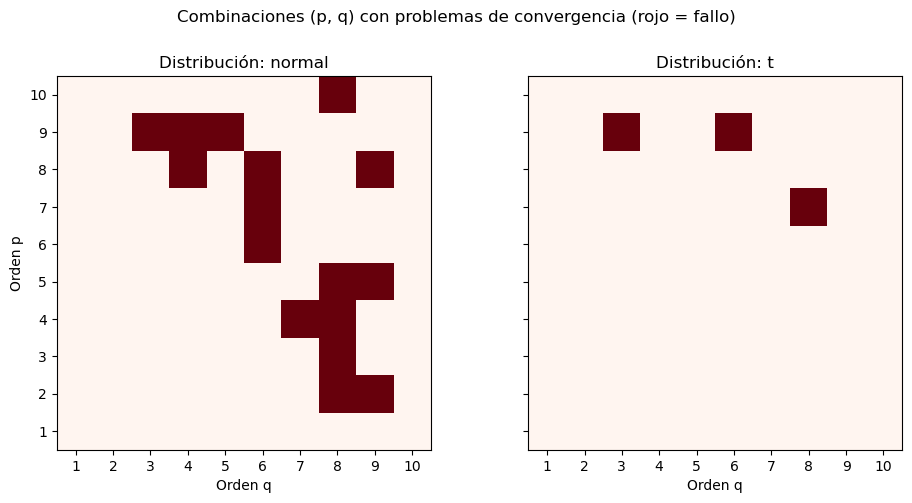

In [35]:
dists = ["normal", "t"]
rows = []

for dist, p, q in itertools.product(dists, range(1, 11), range(1, 11)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = arch_model(
            y_train, mean="Zero", vol="GARCH", p=p, q=q, dist=dist
        ).fit(disp="off")
    rows.append({"dist": dist, "p": p, "q": q, "fallo": int(res.convergence_flag != 0)})

df_conv = pd.DataFrame(rows)

resumen = (
    df_conv.groupby("dist")["fallo"]
    .agg(Fallos="sum", Combinaciones="count")
    .rename_axis("Distribución")
)
resumen["% fallos"] = (100 * resumen["Fallos"] / resumen["Combinaciones"]).round(1)
display(resumen)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
for ax, dist in zip(axes, dists):
    grid = df_conv[df_conv["dist"] == dist].pivot(index="p", columns="q", values="fallo")
    ax.imshow(grid.values, cmap="Reds", vmin=0, vmax=1, origin="lower", aspect="equal")
    ax.set_xticks(range(10))
    ax.set_xticklabels(range(1, 11))
    ax.set_yticks(range(10))
    ax.set_yticklabels(range(1, 11))
    ax.set_title(f"Distribución: {dist}")
    ax.set_xlabel("Orden q")
axes[0].set_ylabel("Orden p")
fig.suptitle("Combinaciones (p, q) con problemas de convergencia (rojo = fallo)", y=1.02)
plt.tight_layout()
plt.show()

Los resultados obtenidos en las cinco réplicas presentan una desviación estándar reducida, lo que evidencia la consistencia del proceso de validación. A partir de los resultados, se observa que la configuración más parsimoniosa, con un orden $(p)$ de 1 y un orden $(q)$ de 1, se sitúa en la primera posición con el menor error global QLIKE, sugiriendo que una menor complejidad es suficiente para capturar adecuadamente la dinámica de la volatilidad en esta fase. Asimismo, la prevalencia de la distribución $t$ de Student en el mejor desempeño es congruente con las colas pesadas y la curtosis elevada documentadas previamente en el EDA.  

In [28]:
tt.display_top_results(
    RESULTS_PATH,
    top_n=5,
    aggregate_mode="mean",
    column_names=(
        "Distribución",
        "Orden (p)",
        "Orden (q)",
        "Réplica 1",
        "Réplica 2",
        "Réplica 3",
        "Réplica 4",
        "Réplica 5",
        "Global (Media ± SD)"
    )
)

Distribución,Orden (p),Orden (q),Réplica 1,Réplica 2,Réplica 3,Réplica 4,Réplica 5,Global (Media ± SD)
t,1,1,0.429 ± 0.108,0.427 ± 0.095,0.425 ± 0.098,0.421 ± 0.092,0.424 ± 0.096,0.425 ± 0.003
ged,1,1,0.432 ± 0.111,0.423 ± 0.095,0.422 ± 0.093,0.429 ± 0.098,0.433 ± 0.107,0.428 ± 0.005
normal,1,1,0.436 ± 0.121,0.424 ± 0.096,0.419 ± 0.091,0.420 ± 0.092,0.442 ± 0.119,0.428 ± 0.010
t,5,5,0.416 ± 0.080,0.452 ± 0.098,0.415 ± 0.090,0.491 ± 0.077,0.419 ± 0.091,0.439 ± 0.033
t,6,6,0.411 ± 0.080,0.423 ± 0.087,0.451 ± 0.097,0.460 ± 0.114,0.465 ± 0.119,0.442 ± 0.024


Para verificar la robustez de los resultados, la agregación se repitió utilizando la mediana y el rango intercuartílico (IQR). A diferencia del error anterior, se observa una total consistencia con la métrica de la media: el criterio de la mediana también favorece de manera clara a la configuración más parsimoniosa con un menor número de rezagos ($p=1, q=1$) bajo las distribuciones GED, $t$ y Normal. Esto demuestra que, tanto al evaluar el error promedio como el comportamiento central de los días típicos de mercado, el modelo GARCH(1,1) ofrece pronósticos más estables y ajustados, evitando la sobreparametrización de los órdenes superiores.

In [29]:
tt.display_top_results(
    RESULTS_PATH, 
    top_n=5, 
    aggregate_mode="median",
    column_names=(
        "Distribución", "Orden (p)",
        "Orden (q)", 
        "Réplica 1", "Réplica 2", "Réplica 3", "Réplica 4", "Réplica 5", 
        "Global (Mediana ± IQR)"
    )
)

Distribución,Orden (p),Orden (q),Réplica 1,Réplica 2,Réplica 3,Réplica 4,Réplica 5,Global (Mediana ± IQR)
ged,1,1,0.430 ± 0.105,0.438 ± 0.103,0.413 ± 0.094,0.410 ± 0.080,0.408 ± 0.110,0.413 ± 0.020
t,1,1,0.430 ± 0.107,0.451 ± 0.096,0.414 ± 0.105,0.410 ± 0.094,0.408 ± 0.090,0.414 ± 0.020
normal,1,1,0.430 ± 0.102,0.438 ± 0.103,0.413 ± 0.098,0.410 ± 0.095,0.425 ± 0.090,0.425 ± 0.017
normal,4,4,0.430 ± 0.117,0.610 ± 0.000,0.422 ± 0.090,0.470 ± 0.155,0.417 ± 0.149,0.430 ± 0.048
t,5,5,0.429 ± 0.058,0.460 ± 0.077,0.425 ± 0.060,0.479 ± 0.099,0.431 ± 0.071,0.431 ± 0.032


Dado que los criterios de la media y la mediana coinciden y que GED y $t$ empatan en (1,1), se selecciona la distribución $t$ de Student con $p=1$ y $q=1$. La elección se apoya en las colas pesadas y la curtosis elevada documentadas en el EDA, y en que es la misma distribución seleccionada por el modelo ARCH, lo que permite comparar ambos modelos en la fase de evaluación y atribuir las diferencias de desempeño a la inclusión del rezago de la varianza condicional. Por esta razón, se omite la representación gráfica de la evolución del QLIKE por orden y distribución, pues las tablas anteriores ya permiten identificar la mejor configuración.

Al cuantificar las diferencias entre los órdenes $q=5$ y $q=6$, se observa que la variación en la pérdida QLIKE es marginal, con una diferencia máxima de 0.004 para la distribución Normal y una diferencia nula para la GED (0.428 frente a 0.429). La distribución $t$ de Student demuestra ser la opción más coherente, ya que logra un desempeño sobresaliente (0.420) con un menor número de parámetros. Aunque la distribución Normal ocupa el primer lugar bajo este criterio específico con $q=6$ (0.419), su desempeño general en la fase de validación fue consistentemente inferior, posicionándose como la peor elección en términos de QLIKE al requerir mayor complejidad para aproximarse a los resultados obtenidos por la distribución $t$.

La tabla de estimación muestra que los parámetros de la ecuación de varianza son significativos ($p < .001$). El coeficiente $\omega$ es prácticamente nulo en la escala de los retornos, lo que indica un nivel basal de varianza bajo. El coeficiente $\alpha_1$ ($0.1000$) refleja una reacción moderada de la volatilidad ante los choques recientes, y $\beta_1$ ($0.8800$) una alta persistencia de la varianza condicional. La suma $\alpha_1 + \beta_1 = 0.98$ es menor que 1, por lo que se cumple la condición de estacionariedad en covarianza, aunque está cerca de la unidad: los choques se disipan lentamente, con una vida media de aproximadamente 34 días hábiles. A diferencia del ARCH(5), donde el optimizador repartía el mismo peso ($0.15$) entre los cinco rezagos, GARCH concentra la dinámica en dos coeficientes con valores diferenciados, lo que ilustra su mayor parsimonia. El parámetro $\nu$ ($5.2599$; IC $3.5194\text{–}5.8790$) corresponde a los grados de libertad de la distribución $t$. Un valor bajo y alejado del infinito confirma la presencia de colas pesadas, valida la elección de esta distribución frente a la Normal y coincide con lo identificado en el EDA.

In [30]:
best_model = GARCHWrapper(
    params={
        "p": 1,
        "q": 1,
        "dist": "t"
    }
)

best_model.fit(y_train)

df_params_boot = best_model.get_parameter_table(
    B=2000,
    decimals=4,
    block_size=22
)

df_params_boot = df_params_boot.rename(columns={
    "Parameter": "Parámetro",
    "Coef": "Coeficiente",
    "Std. Error": "Error Estándar",
    "P-value": "p-valor",
    "CI Lower": "IC Inferior",
    "CI Upper": "IC Superior"
})

tt.display_styled_df(
    df=df_params_boot,
    decimals=4,
    p_value_cols=["p-valor"]
)

Parámetro,Coeficiente,Error Estándar,p-valor,IC Inferior,IC Superior
omega,0.0000,0.0000,< .001,0.0000,0.0001
alpha[1],0.1000,0.0133,< .001,0.0493,0.2000
beta[1],0.8800,0.0098,< .001,0.7000,0.9300
nu,5.2599,0.9276,< .001,3.5194,5.8790


El parámetro $\nu$ (5.2599) define los grados de libertad de la distribución $t$. Un valor bajo y alejado del infinito confirma la presencia de colas pesadas. Este resultado valida empíricamente la elección de la distribución $t$ frente a la Normal. El hallazgo coincide directamente con las propiedades distributivas identificadas en el análisis exploratorio de datos.

Las pruebas de Ljung-Box y ARCH-LM indican que el modelo capturó la estructura de dependencia temporal. No quedan patrones de autocorrelación ni efectos de heterocedasticidad condicional residuales en ninguno de los rezagos evaluados, incluso tras el ajuste de Bonferroni. El test BDS no encuentra evidencia de estructura no lineal remanente. Las pruebas de Jarque-Bera y Lilliefors rechazan la normalidad de los residuos estandarizados, un resultado esperable, pues el modelo supone innovaciones $t$ de Student y no Normales. En conjunto, los residuos no muestran dependencia lineal ni no lineal, por lo que la especificación GARCH(1,1) resulta adecuada para describir la dinámica de la volatilidad.

In [31]:
std_residuals = best_model.model_fit.std_resid

df_diag = tt.run_model_diagnostics(
    std_residuals=std_residuals,
    lags=(10, 20, 30),
    p_adjust="bonferroni",
    alpha=0.05,
    column_titles=(
        "Prueba Estadística",
        "Estadístico",
        "p-valor",
        "p-ajustado (Bonferroni)",
        "Conclusión (α = 0.05)"
    )
)

tt.display_styled_df(
    df=df_diag,
    decimals=3,
    p_value_cols=["p-valor", "p-ajustado"]
)

Prueba Estadística,Estadístico,p-valor,p-ajustado (Bonferroni),Conclusión (α = 0.05)
Ljung-Box (Lag 10),7.312451,.696,1.000,Sin Autocorrelación
Ljung-Box (Lag 20),25.667436,.177,.531,Sin Autocorrelación
Ljung-Box (Lag 30),36.403052,.195,.586,Sin Autocorrelación
ARCH-LM (Lag 10),6.709372,.753,1.000,Sin Efectos ARCH
ARCH-LM (Lag 20),10.260009,.963,1.000,Sin Efectos ARCH
ARCH-LM (Lag 30),27.599222,.592,1.000,Sin Efectos ARCH
Jarque-Bera,2227.223876,< .001,< .001,Residuos No Normales
Lilliefors,0.053459,< .001,.002,Residuos No Normales
BDS (Dim 2),0.6328082214814665,.527,.527,Sin Estructura No Lineal


La figura ilustra el ajuste in-sample del modelo GARCH(1,1) con distribución $t$ de Student frente a la volatilidad realizada. La serie condicional reproduce la dinámica general durante los periodos de fluctuación moderada y captura los clústeres de volatilidad de 2015-2016, 2019 y 2022. Gracias al término autorregresivo de la varianza, la volatilidad condicional es más suave que la realizada y decae de forma gradual tras cada episodio, lo que refleja la alta persistencia estimada ($\alpha_1 + \beta_1 = 0.98$). Al inicio de la muestra (2014) se observa un ligero sobreajuste, con una volatilidad condicional superior a la realizada, atribuible al periodo de arranque del filtro de varianza. 

El comportamiento diverge durante el shock extremo de 2020. La volatilidad realizada registra un incremento abrupto e inusual, con picos entre 0.15 y 0.25. La volatilidad condicional se eleva, pero se mantiene en torno a 0.10, por lo que subestima la magnitud del evento. Tras el pico, la serie condicional permanece por encima de la realizada durante varios meses, consecuencia de la lenta disipación del choque. Una limitación similar aparece en el episodio de 2022, donde la realizada supera 0.11 y la condicional alcanza cerca de 0.05. Aunque GARCH reacciona con mayor rapidez y persistencia que ARCH, su estructura sigue sin asimilar saltos abruptos de volatilidad, pues la varianza condicional responde a los choques con rezago.  

In [ ]:
pred_vol_train = best_model.model_fit.conditional_volatility

tk.plot_volatility_fit(
    dates=df_train.index,
    rs=rs_train,
    pred_vol=pred_vol_train,
    title="Volatilidad Realizada vs Condicional - GARCH (Entrenamiento)",
    legend_size=13,
    legend_loc="upper left"
)

## Evaluación

La tabla compara las métricas de desempeño entre el conjunto de entrenamiento (In-Sample) y el de prueba (Out-of-Sample) mediante la diferencia absoluta $\Delta_{abs} = M_{test} - M_{train}$, que se contrasta con los umbrales de tolerancia definidos para el diagnóstico de sobreajuste. Para la métrica principal, el QLIKE pasa de 0.3897 en entrenamiento a 0.4147 en prueba, con un $\Delta_{abs}$ de +0.0250, por debajo del umbral de 0.05, por lo que no hay pérdida de capacidad predictiva fuera de muestra. Las métricas de error puntual presentan variaciones del orden esperado: el MSE aumenta en $10^{-6}$ (+0.000001), el MAE en $6 \times 10^{-6}$ (+0.000006) y el RMSE en $3.42 \times 10^{-4}$ (+0.000342), todas dentro de los márgenes de $10^{-4}$ a $10^{-6}$ que denotan estabilidad predictiva. Las métricas probabilísticas muestran diferencias negativas, es decir, valores ligeramente inferiores en prueba: el CRPS cambia en $-1.89 \times 10^{-4}$ y el Pinball Loss en $-8.4 \times 10^{-5}$ ($\tau = 0.05$) y $-7.9 \times 10^{-5}$ ($\tau = 0.95$), también dentro de los márgenes establecidos, lo que sugiere que la distribución $t$ describe adecuadamente las colas fuera de muestra. El incremento relativo del RMSE (+18.8 %), mayor que el del MAE (+1.3 %), indica que el deterioro se concentra en pocos días de volatilidad extrema, como el shock de inicios de 2026, y no en un desajuste generalizado. Como ninguna métrica supera de forma sustancial su umbral, no hay evidencia de sobreajuste y el modelo conserva una capacidad de generalización estable sobre datos no vistos.

In [ ]:
scorer = VolatilityScorer()

q_context = best_model.context_length

predictions_test = best_model.forecast(
    y_target=y_test,
    initial_context=y_train[-q_context:]
)

tk.display_train_test_comparison(
    model=best_model,
    scorer=scorer,
    rs_train=rs_train,
    rs_test=rs_test,
    preds_test=predictions_test,
    dist="t",
    nu=best_model.model_fit.params["nu"],
    decimals=6,
    column_titles=(
        "Métrica",
        "Entrenamiento",
        "Prueba",
        "Diferencia"
    ),
    show_diff=True
)

Métrica,Entrenamiento,Prueba,Diferencia
QLIKE,0.389721,0.414742,+0.025020
MSE,0.000003,0.000005,+0.000001
RMSE,0.001818,0.002160,+0.000342
MAE,0.000454,0.000460,+0.000006
CRPS,0.004782,0.004593,-0.000189
Pinball (τ=0.05),0.001874,0.001791,-0.000084
Pinball (τ=0.95),0.001813,0.001734,-0.000079


El desempeño predictivo es consistente con la fase de entrenamiento. La serie condicional reproduce la tendencia general de la volatilidad realizada durante los periodos de fluctuación moderada, con un nivel base cercano a 0.02 entre finales de 2022 y comienzos de 2025. Se mantiene la misma limitación estructural observada previamente: los picos aislados de 2025, donde la volatilidad realizada alcanza cerca de 0.08, solo elevan la condicional a niveles entre 0.03 y 0.04. El caso más claro es el shock extremo de inicios de 2026, donde la volatilidad realizada supera 0.25 y la condicional alcanza apenas cerca de 0.07, menos de un tercio del valor observado. Como los pronósticos son a un paso, la condicional reacciona con rezago: sube en los días posteriores al pico y no en el día del evento.

Tras el shock, la volatilidad condicional decae de forma gradual y permanece por encima de la realizada durante varios meses, reflejo de la alta persistencia estimada ($\alpha_1 + \beta_1 = 0.98$). Este patrón replica lo observado in-sample y es coherente con el deterioro de RMSE y QLIKE en prueba, concentrado en pocos días extremos. En conjunto, el modelo conserva su estabilidad predictiva, pero no logra asimilar saltos abruptos de volatilidad.

In [ ]:
pred_vol_test = np.sqrt(predictions_test)

tk.plot_volatility_fit(
    dates=df_test.index,
    rs=rs_test,
    pred_vol=pred_vol_test,
    title="Volatilidad Realizada vs Condicional - GARCH (Prueba)",
    legend_loc="upper left",
    legend_size=13
)